In [1]:
from pathlib import Path
from collections import Counter
import pandas as pd

ROOT = Path(
    r"C:\Users\dipto\Downloads\Projects\Imran Journal 2 work"
)

# Count all files, including files inside extracted folders
files = [p for p in ROOT.rglob("*") if p.is_file()]

extensions = Counter(
    p.suffix.lower() or "(no extension)"
    for p in files
)

inventory = pd.DataFrame(
    extensions.items(),
    columns=["File Type", "Count"]
).sort_values("Count", ascending=False)

print(f"Total files: {len(files)}")
display(inventory)

print("\nTop-level files and folders:")
for p in sorted(ROOT.iterdir()):
    print("DIR " if p.is_dir() else "FILE", p.name)

Total files: 4


,File Type,Count
0,.zip,2
1,.ipynb,2



Top-level files and folders:
DIR  .ipynb_checkpoints
FILE Document-OCR.zip
DIR  notebooks
FILE optical_topology_dataset.zip
DIR  results
DIR  scripts
FILE Untitled.ipynb


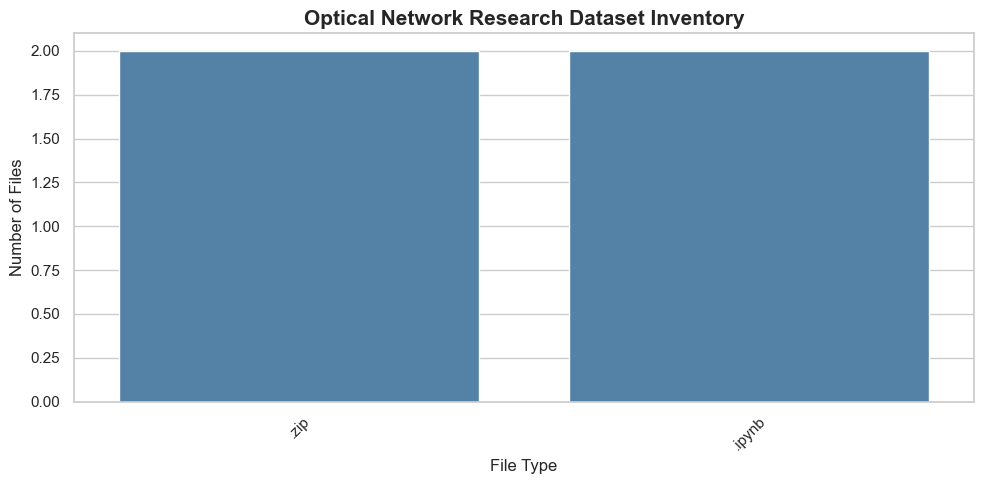

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=inventory,
    x="File Type",
    y="Count",
    color="steelblue",
    ax=ax
)

ax.set_title(
    "Optical Network Research Dataset Inventory",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("File Type")
ax.set_ylabel("Number of Files")

plt.xticks(rotation=45)
plt.tight_layout()

output = ROOT / "results" / "figures"
output.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output / "dataset_inventory.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [3]:
from pathlib import Path
from zipfile import ZipFile
from collections import Counter
import pandas as pd

ROOT = Path(
    r"C:\Users\dipto\Downloads\Projects\Imran Journal 2 work"
)

for zip_path in sorted(ROOT.glob("*.zip")):

    print(f"\n{'=' * 65}")
    print(f"ARCHIVE: {zip_path.name}")
    print(f"{'=' * 65}")

    with ZipFile(zip_path) as archive:
        files = [
            f for f in archive.infolist()
            if not f.is_dir()
        ]

        extensions = Counter(
            Path(f.filename).suffix.lower()
            for f in files
        )

        print(f"Total files inside: {len(files)}")
        print("\nFile types:")

        display(
            pd.DataFrame(
                extensions.items(),
                columns=["Extension", "Count"]
            ).sort_values("Count", ascending=False)
        )

        print("\nFirst 20 files:")
        for f in files[:20]:
            print(" ", f.filename)


ARCHIVE: Document-OCR.zip
Total files inside: 593

File types:


,Extension,Count
1,.py,405
9,.pyc,103
0,,33
8,.typed,14
5,.txt,13
11,.exe,8
4,.md,4
7,.bat,2
12,.apache,2
13,.bsd,2



First 20 files:
  Document-OCR/.gitignore
  Document-OCR/app.py
  Document-OCR/ChatGPT.pdf
  Document-OCR/Conclusions.pptx
  Document-OCR/config.py
  Document-OCR/example.py
  Document-OCR/QUICK_START.md
  Document-OCR/README.md
  Document-OCR/requirements.txt
  Document-OCR/Screenshot 2026-02-04 163447.png
  Document-OCR/standalone_ocr_app_.py
  Document-OCR/standalone_topology_extractor_app.py
  Document-OCR/start.bat
  Document-OCR/start_streamlit.bat
  Document-OCR/test_environment.py
  Document-OCR/utils.py
  Document-OCR/venv/.gitignore
  Document-OCR/venv/Lib/site-packages/pip/py.typed
  Document-OCR/venv/Lib/site-packages/pip/_internal/build_env.py
  Document-OCR/venv/Lib/site-packages/pip/_internal/cache.py

ARCHIVE: optical_topology_dataset.zip
Total files inside: 1514

File types:


,Extension,Count
3,.txt,503
1,.json,501
2,.png,500
4,.pdf,5
6,.py,3
0,.yaml,1
5,.url,1



First 20 files:
  optical_topology_dataset/dataset.yaml
  optical_topology_dataset/generation_config.json
  optical_topology_dataset/graphs/topo_0001.json
  optical_topology_dataset/graphs/topo_0002.json
  optical_topology_dataset/graphs/topo_0003.json
  optical_topology_dataset/graphs/topo_0004.json
  optical_topology_dataset/graphs/topo_0005.json
  optical_topology_dataset/graphs/topo_0006.json
  optical_topology_dataset/graphs/topo_0007.json
  optical_topology_dataset/graphs/topo_0008.json
  optical_topology_dataset/graphs/topo_0009.json
  optical_topology_dataset/graphs/topo_0010.json
  optical_topology_dataset/graphs/topo_0011.json
  optical_topology_dataset/graphs/topo_0012.json
  optical_topology_dataset/graphs/topo_0013.json
  optical_topology_dataset/graphs/topo_0014.json
  optical_topology_dataset/graphs/topo_0015.json
  optical_topology_dataset/graphs/topo_0016.json
  optical_topology_dataset/graphs/topo_0017.json
  optical_topology_dataset/graphs/topo_0018.json


,Dataset,File Type,Count
0,Document-OCR,.apache,2
1,Document-OCR,.bat,2
2,Document-OCR,.bsd,2
3,Document-OCR,.cfg,1
4,Document-OCR,.exe,8
5,Document-OCR,.md,4
6,Document-OCR,.pdf,1
7,Document-OCR,.pem,1
8,Document-OCR,.png,1
9,Document-OCR,.pptx,1


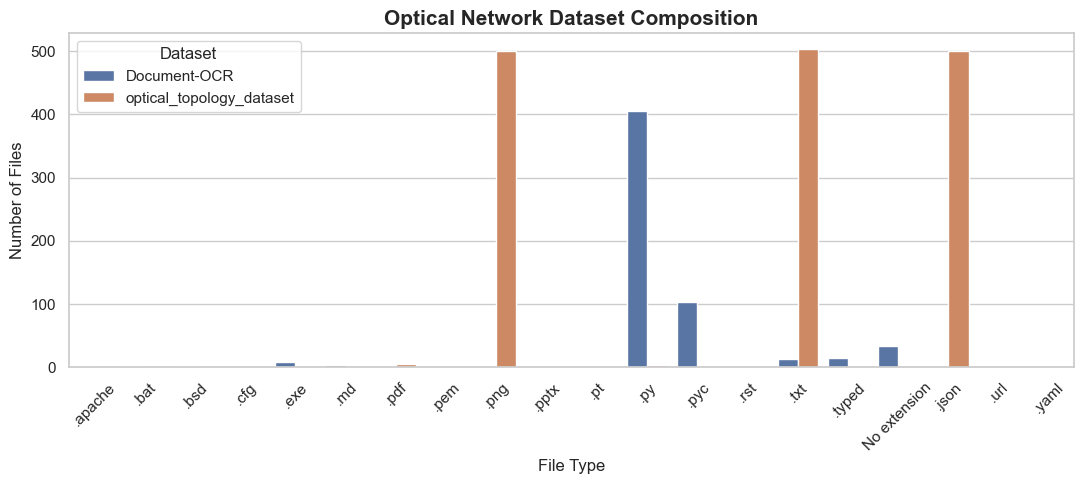

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

records = []

for zip_path in ROOT.glob("*.zip"):
    with ZipFile(zip_path) as archive:
        for f in archive.infolist():
            if not f.is_dir():
                records.append({
                    "Dataset": zip_path.stem,
                    "File Type": (
                        Path(f.filename).suffix.lower()
                        or "No extension"
                    ),
                    "Size (KB)": f.file_size / 1024
                })

df = pd.DataFrame(records)

summary = (
    df.groupby(["Dataset", "File Type"])
      .size()
      .reset_index(name="Count")
)

display(summary)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=summary,
    x="File Type",
    y="Count",
    hue="Dataset"
)

plt.title(
    "Optical Network Dataset Composition",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("File Type")
plt.ylabel("Number of Files")
plt.xticks(rotation=45)
plt.tight_layout()

output_dir = ROOT / "results" / "figures"
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "dataset_composition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
import json
from zipfile import ZipFile
from pathlib import Path
from pprint import pprint

ROOT = Path(
    r"C:\Users\dipto\Downloads\Projects\Imran Journal 2 work"
)

zip_path = ROOT / "optical_topology_dataset.zip"

with ZipFile(zip_path) as archive:

    # Find the graph annotation files
    graph_files = sorted(
        name for name in archive.namelist()
        if "/graphs/" in name
        and name.endswith(".json")
    )

    print("Total graph annotations:", len(graph_files))

    # Inspect three examples
    for filename in graph_files[:3]:

        print("\n" + "=" * 60)
        print("FILE:", filename)
        print("=" * 60)

        data = json.loads(
            archive.read(filename).decode("utf-8")
        )

        pprint(data, sort_dicts=False)

    # Inspect generation configuration
    config_file = next(
        name for name in archive.namelist()
        if name.endswith("generation_config.json")
    )

    print("\nGENERATION CONFIGURATION")
    pprint(
        json.loads(
            archive.read(config_file).decode("utf-8")
        ),
        sort_dicts=False
    )

Total graph annotations: 500

FILE: optical_topology_dataset/graphs/topo_0001.json
{'sample_id': 'topo_0001',
 'image': 'topo_0001.png',
 'topology_type': 'ring',
 'nodes': [{'id': 'A'}, {'id': 'B'}, {'id': 'C'}],
 'edges': [{'source': 'A', 'target': 'B', 'distance_km': 180},
           {'source': 'A', 'target': 'C', 'distance_km': 380},
           {'source': 'B', 'target': 'C', 'distance_km': 210}]}

FILE: optical_topology_dataset/graphs/topo_0002.json
{'sample_id': 'topo_0002',
 'image': 'topo_0002.png',
 'topology_type': 'star',
 'nodes': [{'id': 'A'}, {'id': 'B'}, {'id': 'C'}, {'id': 'D'}],
 'edges': [{'source': 'A', 'target': 'B', 'distance_km': 60},
           {'source': 'A', 'target': 'C', 'distance_km': 390},
           {'source': 'A', 'target': 'D', 'distance_km': 270}]}

FILE: optical_topology_dataset/graphs/topo_0003.json
{'sample_id': 'topo_0003',
 'image': 'topo_0003.png',
 'topology_type': 'ring',
 'nodes': [{'id': 'A'}, {'id': 'B'}, {'id': 'C'}, {'id': 'D'}],
 'edges': [

Total graphs: 500
Total edge records: 1760
Validation issues: 0

Topology distribution:


topology_type
ring    255
star    245
Name: count, dtype: int64


Graph statistics:


,num_nodes,num_edges,density,avg_degree,diameter,total_distance_km
count,500.00,500.00,500.00,500.00,500.00,500.00
mean,4.01,3.52,0.62,1.75,1.83,794.04
std,0.80,0.92,0.20,0.27,0.38,288.42
min,3.00,2.00,0.40,1.33,1.00,170.00
25%,3.00,3.00,0.50,1.50,2.00,577.50
50%,4.00,4.00,0.58,2.00,2.00,780.00
75%,5.00,4.00,0.67,2.00,2.00,972.50
max,5.00,5.00,1.00,2.00,2.00,1670.00


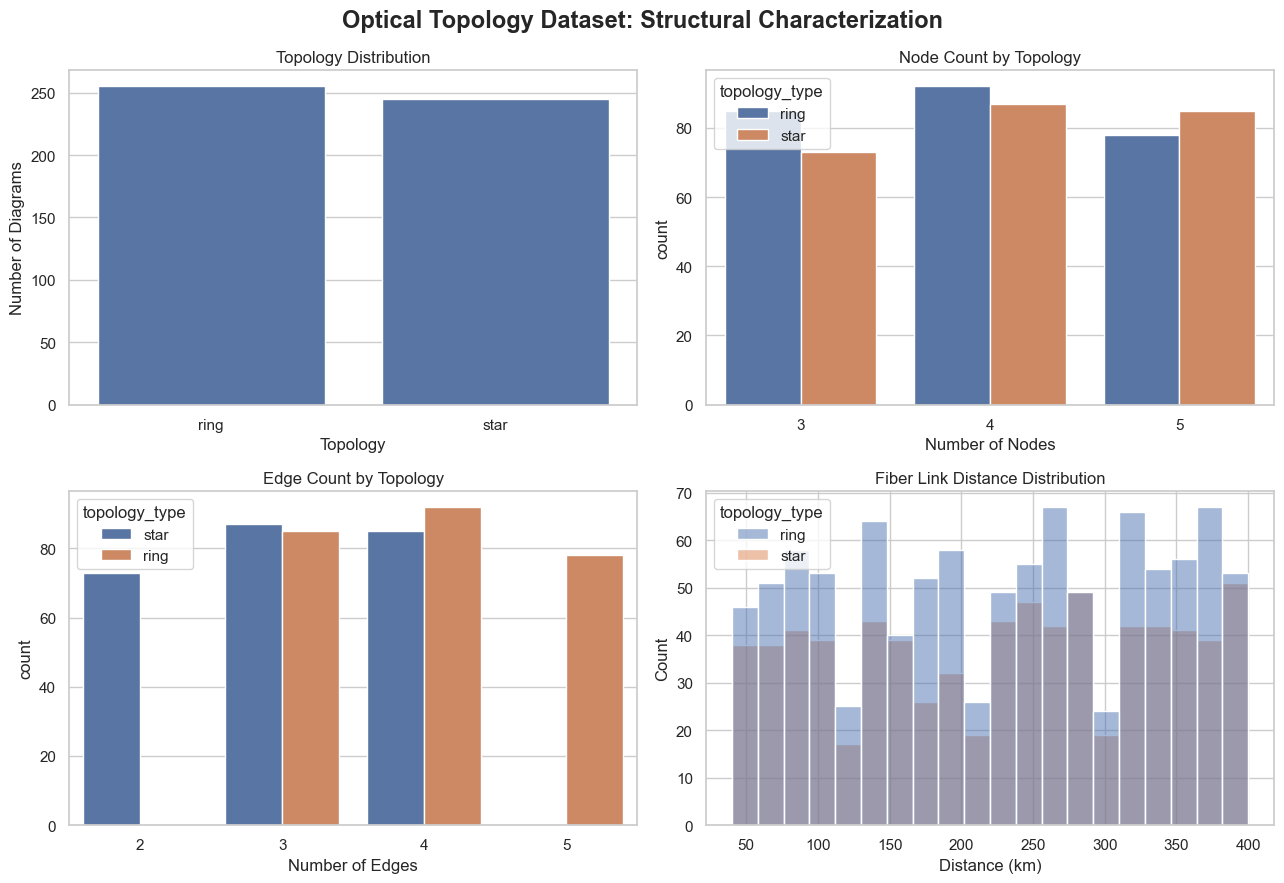

In [6]:
import json
from pathlib import Path
from zipfile import ZipFile

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path(
    r"C:\Users\dipto\Downloads\Projects\Imran Journal 2 work"
)

ZIP_PATH = ROOT / "optical_topology_dataset.zip"
OUTPUT = ROOT / "results"
FIGURES = OUTPUT / "figures"
STATISTICS = OUTPUT / "statistics"

FIGURES.mkdir(parents=True, exist_ok=True)
STATISTICS.mkdir(parents=True, exist_ok=True)

graph_records = []
edge_records = []
validation_issues = []

with ZipFile(ZIP_PATH) as archive:

    graph_files = sorted(
        name for name in archive.namelist()
        if "/graphs/" in name and name.endswith(".json")
    )

    for filename in graph_files:
        data = json.loads(archive.read(filename))

        sample_id = data["sample_id"]
        topology = data["topology_type"]
        nodes = data["nodes"]
        edges = data["edges"]

        node_ids = [node["id"] for node in nodes]

        G = nx.Graph()
        G.add_nodes_from(node_ids)

        if len(node_ids) != len(set(node_ids)):
            validation_issues.append(
                (sample_id, "Duplicate node IDs")
            )

        seen_edges = set()

        for edge in edges:
            source = edge["source"]
            target = edge["target"]
            distance = edge["distance_km"]

            if source not in node_ids or target not in node_ids:
                validation_issues.append(
                    (sample_id, "Edge references unknown node")
                )
                continue

            if source == target:
                validation_issues.append(
                    (sample_id, "Self-loop")
                )

            edge_key = tuple(sorted((source, target)))

            if edge_key in seen_edges:
                validation_issues.append(
                    (sample_id, "Duplicate edge")
                )

            seen_edges.add(edge_key)

            if not isinstance(distance, (int, float)) or distance <= 0:
                validation_issues.append(
                    (sample_id, "Invalid distance")
                )
                continue

            G.add_edge(
                source,
                target,
                distance_km=distance
            )

            edge_records.append({
                "sample_id": sample_id,
                "topology_type": topology,
                "source": source,
                "target": target,
                "distance_km": distance
            })

        connected = nx.is_connected(G)

        degrees = [degree for _, degree in G.degree()]

        graph_records.append({
            "sample_id": sample_id,
            "topology_type": topology,
            "num_nodes": G.number_of_nodes(),
            "num_edges": G.number_of_edges(),
            "density": nx.density(G),
            "avg_degree": np.mean(degrees),
            "max_degree": max(degrees),
            "connected": connected,
            "diameter": nx.diameter(G) if connected else np.nan,
            "total_distance_km": sum(
                attr["distance_km"]
                for _, _, attr in G.edges(data=True)
            )
        })

graphs_df = pd.DataFrame(graph_records)
edges_df = pd.DataFrame(edge_records)

graphs_df.to_csv(
    STATISTICS / "graph_statistics.csv",
    index=False
)

edges_df.to_csv(
    STATISTICS / "edge_statistics.csv",
    index=False
)

pd.DataFrame(
    validation_issues,
    columns=["sample_id", "issue"]
).to_csv(
    STATISTICS / "validation_issues.csv",
    index=False
)

print("Total graphs:", len(graphs_df))
print("Total edge records:", len(edges_df))
print("Validation issues:", len(validation_issues))

print("\nTopology distribution:")
display(graphs_df["topology_type"].value_counts())

print("\nGraph statistics:")
display(
    graphs_df[
        [
            "num_nodes",
            "num_edges",
            "density",
            "avg_degree",
            "diameter",
            "total_distance_km"
        ]
    ].describe().round(2)
)

# Four-panel visualization
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.countplot(
    data=graphs_df,
    x="topology_type",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Topology Distribution")
axes[0, 0].set_xlabel("Topology")
axes[0, 0].set_ylabel("Number of Diagrams")

sns.countplot(
    data=graphs_df,
    x="num_nodes",
    hue="topology_type",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Node Count by Topology")
axes[0, 1].set_xlabel("Number of Nodes")

sns.countplot(
    data=graphs_df,
    x="num_edges",
    hue="topology_type",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Edge Count by Topology")
axes[1, 0].set_xlabel("Number of Edges")

sns.histplot(
    data=edges_df,
    x="distance_km",
    hue="topology_type",
    bins=20,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Fiber Link Distance Distribution")
axes[1, 1].set_xlabel("Distance (km)")

fig.suptitle(
    "Optical Topology Dataset: Structural Characterization",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    FIGURES / "dataset_structural_characterization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
from collections import Counter, defaultdict
from zipfile import ZipFile
import json
import pandas as pd
import networkx as nx

graphs = []

with ZipFile(ZIP_PATH) as archive:
    for name in sorted(archive.namelist()):
        if "/graphs/" not in name or not name.endswith(".json"):
            continue

        data = json.loads(archive.read(name))

        G = nx.Graph()
        G.add_nodes_from(n["id"] for n in data["nodes"])

        for e in data["edges"]:
            G.add_edge(e["source"], e["target"])

        graphs.append({
            "sample_id": data["sample_id"],
            "topology_type": data["topology_type"],
            "graph": G
        })

# Group graphs by exact structural isomorphism.
# Edge distances and node labels are intentionally ignored.
groups = []

for item in graphs:
    found = False

    for group in groups:
        if nx.is_isomorphic(
            item["graph"],
            group["representative"]
        ):
            group["members"].append(item["sample_id"])
            found = True
            break

    if not found:
        groups.append({
            "representative": item["graph"],
            "members": [item["sample_id"]],
            "topology_type": item["topology_type"]
        })

rows = []

for i, group in enumerate(groups, start=1):
    G = group["representative"]

    rows.append({
        "structure_id": f"S{i:02d}",
        "topology_type": group["topology_type"],
        "num_nodes": G.number_of_nodes(),
        "num_edges": G.number_of_edges(),
        "num_samples": len(group["members"])
    })

diversity_df = pd.DataFrame(rows).sort_values(
    "num_samples",
    ascending=False
)

display(diversity_df)

print("Total diagrams:", len(graphs))
print("Unique unweighted graph structures:", len(groups))
print(
    "Structural uniqueness ratio:",
    round(len(groups) / len(graphs), 4)
)

diversity_df.to_csv(
    STATISTICS / "structural_diversity.csv",
    index=False
)

,structure_id,topology_type,num_nodes,num_edges,num_samples
2,S03,ring,4,4,92
1,S02,star,4,3,87
0,S01,ring,3,3,85
4,S05,star,5,4,85
5,S06,ring,5,5,78
3,S04,star,3,2,73


Total diagrams: 500
Unique unweighted graph structures: 6
Structural uniqueness ratio: 0.012


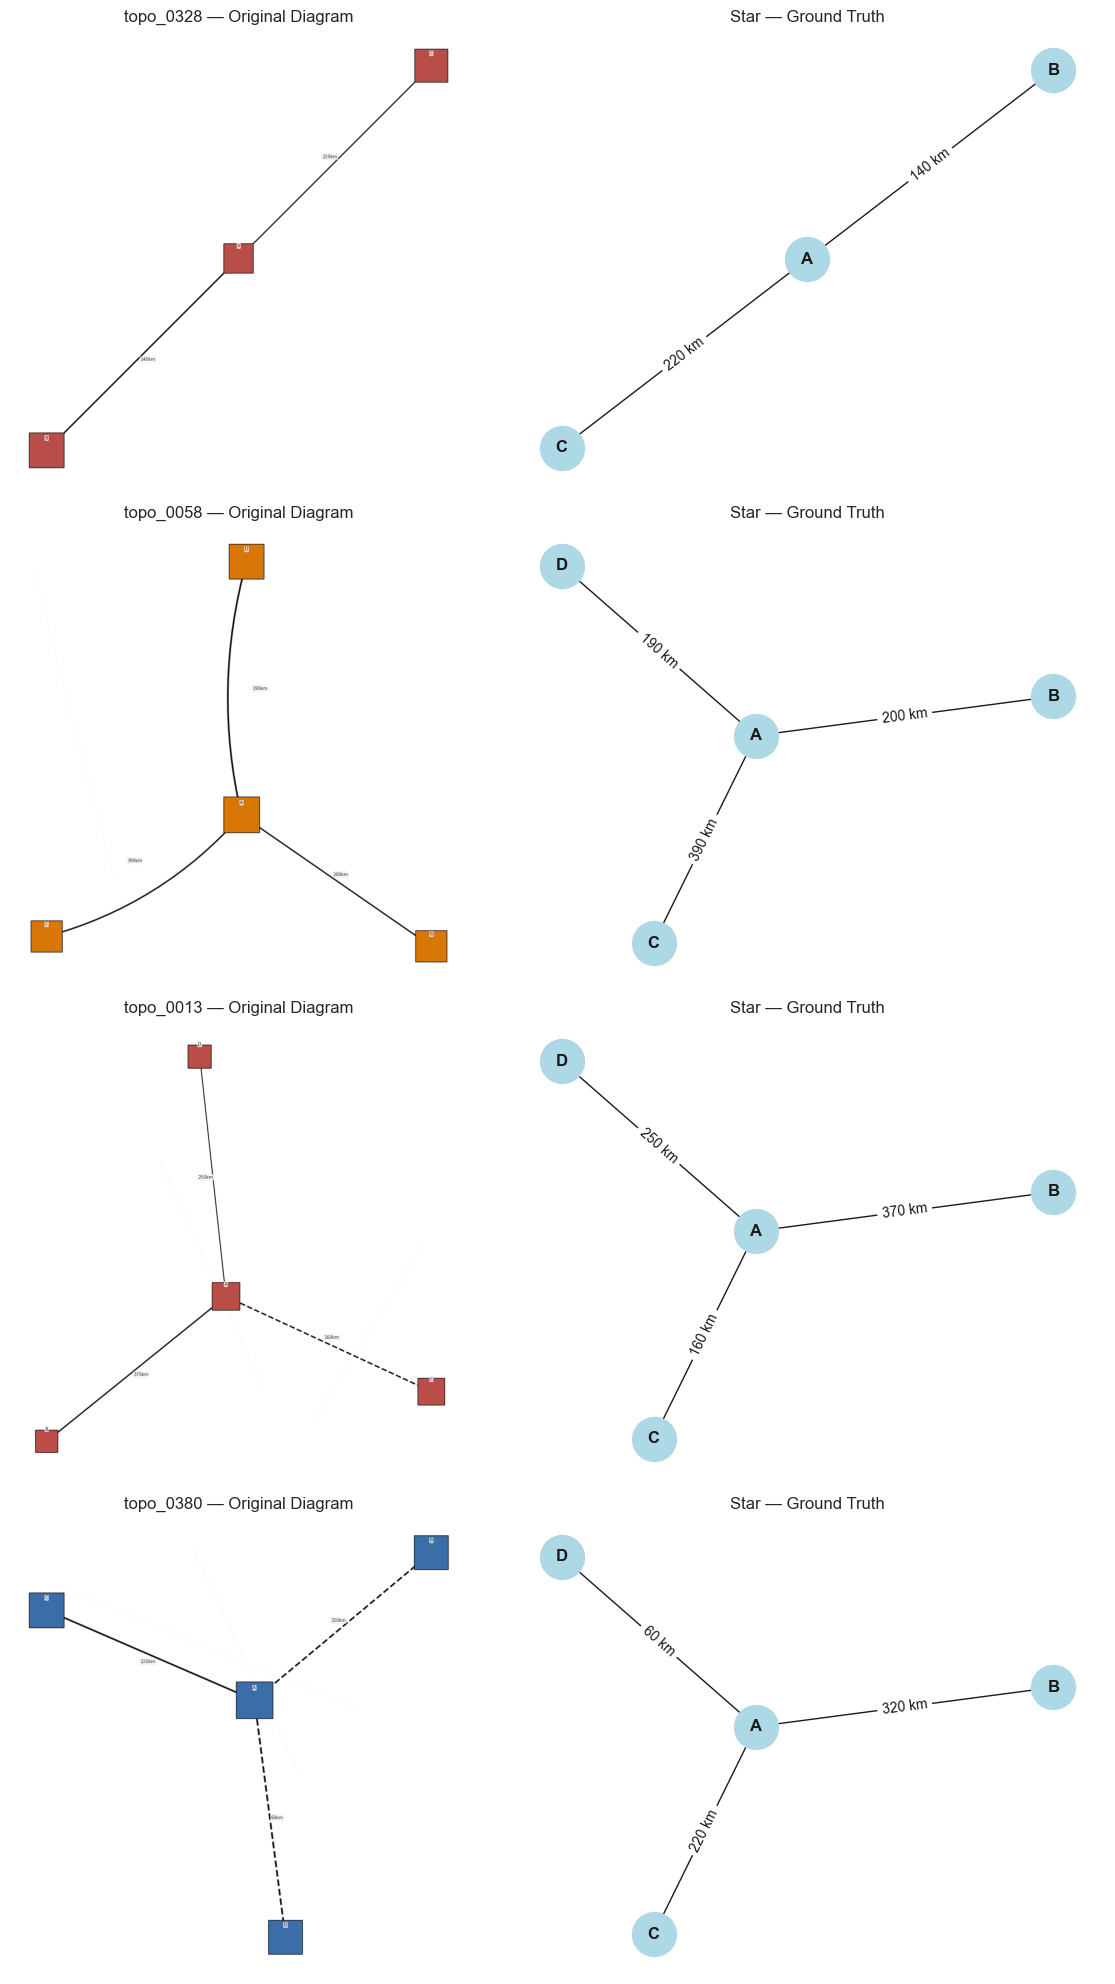

In [8]:
import json
import random
from io import BytesIO
from zipfile import ZipFile

import matplotlib.pyplot as plt
import networkx as nx
from PIL import Image

random.seed(42)

with ZipFile(ZIP_PATH) as archive:

    names = archive.namelist()

    graph_files = sorted(
        n for n in names
        if "/graphs/" in n and n.endswith(".json")
    )

    selected = random.sample(graph_files, 4)

    fig, axes = plt.subplots(
        4, 2,
        figsize=(12, 20)
    )

    for row, graph_file in enumerate(selected):

        data = json.loads(archive.read(graph_file))
        image_name = data["image"]

        candidates = [
            n for n in names
            if n.endswith("/" + image_name)
        ]

        if not candidates:
            print("Missing image:", image_name)
            continue

        image = Image.open(
            BytesIO(archive.read(candidates[0]))
        ).convert("RGB")

        axes[row, 0].imshow(image)
        axes[row, 0].set_title(
            f"{data['sample_id']} — Original Diagram"
        )
        axes[row, 0].axis("off")

        G = nx.Graph()

        for node in data["nodes"]:
            G.add_node(node["id"])

        for edge in data["edges"]:
            G.add_edge(
                edge["source"],
                edge["target"],
                distance=edge["distance_km"]
            )

        pos = nx.spring_layout(G, seed=42)

        nx.draw_networkx(
            G,
            pos,
            ax=axes[row, 1],
            node_color="lightblue",
            node_size=1000,
            font_size=12,
            font_weight="bold"
        )

        edge_labels = nx.get_edge_attributes(
            G, "distance"
        )

        nx.draw_networkx_edge_labels(
            G,
            pos,
            edge_labels={
                k: f"{v} km"
                for k, v in edge_labels.items()
            },
            ax=axes[row, 1]
        )

        axes[row, 1].set_title(
            f"{data['topology_type'].title()} — Ground Truth"
        )
        axes[row, 1].axis("off")

    plt.tight_layout()

    plt.savefig(
        FIGURES / "diagram_vs_ground_truth.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [9]:
from zipfile import ZipFile

with ZipFile(ZIP_PATH) as archive:
    python_files = [
        name for name in archive.namelist()
        if name.endswith(".py")
    ]

    print("Python scripts inside the dataset:")
    for name in python_files:
        print(" -", name)

Python scripts inside the dataset:
 - data-generator.py
 - pix2struct_eval.py
 - pix2struct_train.py


In [10]:
from zipfile import ZipFile

with ZipFile(ZIP_PATH) as archive:
    filename = next(
        name for name in archive.namelist()
        if name.endswith("data-generator.py")
    )

    source = archive.read(filename).decode(
        "utf-8", errors="replace"
    )

    print("Generator:", filename)
    print("Total lines:", len(source.splitlines()))
    print("\n" + "=" * 70)
    print(source)

Generator: data-generator.py
Total lines: 913

#C:/Users/hahassan/AppData/Local/Programs/Python/Python313/python.exe app.py --output-dir optical_topology_dataset --num-samples 40 --train-ratio 0.75 --val-ratio 0.125 --clear-existing
#python data-generator.py --output-dir optical_topology_dataset --num-samples 40 --train-ratio 0.75 --val-ratio 0.125 --clear-existing

from __future__ import annotations  

import argparse
import json
import math
import random
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Mapping, Sequence, Tuple

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from matplotlib.patches import FancyArrowPatch
import networkx as nx

TOPOLOGY_OPTIONS = ("mesh", "ring", "star", "random")

# Distance label placement tuning.
STRAIGHT_LABEL_OFFSET = 0.016
CURVED_LABEL_BASE_OFFSET = 0.0035
CURVED_LABEL_CURVATURE_FACTOR = 0.0065
CURVED_LABEL_LENGTH_FACTOR = 0.004
CURVED_LABEL_MAX_OF

In [11]:
output_path = ROOT / "scripts" / "data-generator.py"
output_path.parent.mkdir(parents=True, exist_ok=True)

output_path.write_text(source, encoding="utf-8")

print("Saved to:", output_path)

Saved to: C:\Users\dipto\Downloads\Projects\Imran Journal 2 work\scripts\data-generator.py
